In [14]:
#Ok let's open the data

import pandas as pd
from pathlib import Path
PARENT_PATH_DATA = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_26_sensor_comparisons/data"


data_path_temperature = Path(PARENT_PATH_DATA)/"boston_temp_combined.csv"
data_path_pm25 = Path(PARENT_PATH_DATA)/"boston_pm25_combined.csv"


temperature_data = pd.read_csv(data_path_temperature)
pm25_data = pd.read_csv(data_path_pm25)
#Let's print the header to see what we are dealing with
print(f"Temperature columns {list(temperature_data.columns)}")
print(f"PM-2.5 columns {list(pm25_data.columns)}")

roxbury_data = temperature_data[temperature_data["site_name"] == "DUDLEY SQUARE ROXBURY"]
hillern_data = temperature_data[temperature_data["site_name"] == "VON HILLERN ST"]

def convert_from_fahrenheit_to_celsius(value):
    return (value - 32)*(5/9)


roxbury_data["temp_f"] = roxbury_data["temp_f"].map(convert_from_fahrenheit_to_celsius)
hillern_data["temp_f"] = hillern_data["temp_f"].map(convert_from_fahrenheit_to_celsius)

Temperature columns ['date', 'year', 'month', 'mo', 'doy', 'site', 'site_name', 'lat', 'lon', 'temp_f', 'temp_max_f', 'units', 'n_obs', 'method']
PM-2.5 columns ['date', 'year', 'month', 'mo', 'doy', 'site', 'site_name', 'lat', 'lon', 'pm25', 'aqi', 'units', 'n_obs', 'method']


['DUDLEY SQUARE ROXBURY' 'VON HILLERN ST']
#ff79c6
Points temperature 1577
Points dates 1577
DUDLEY SQUARE ROXBURY
2024-01-01
DUDLEY SQUARE ROXBURY
2024-01-02
DUDLEY SQUARE ROXBURY
2024-01-03
DUDLEY SQUARE ROXBURY
2024-01-04
DUDLEY SQUARE ROXBURY
2024-01-05
DUDLEY SQUARE ROXBURY
2024-01-06
DUDLEY SQUARE ROXBURY
2024-01-07
DUDLEY SQUARE ROXBURY
2024-01-08
DUDLEY SQUARE ROXBURY
2024-01-09
DUDLEY SQUARE ROXBURY
2024-01-10
DUDLEY SQUARE ROXBURY
2024-01-11
DUDLEY SQUARE ROXBURY
2024-01-12
DUDLEY SQUARE ROXBURY
2024-01-13
DUDLEY SQUARE ROXBURY
2024-01-14
DUDLEY SQUARE ROXBURY
2024-01-15
DUDLEY SQUARE ROXBURY
2024-01-16
DUDLEY SQUARE ROXBURY
2024-01-17
DUDLEY SQUARE ROXBURY
2024-01-18
DUDLEY SQUARE ROXBURY
2024-01-19
DUDLEY SQUARE ROXBURY
2024-01-20
DUDLEY SQUARE ROXBURY
2024-01-21
DUDLEY SQUARE ROXBURY
2024-01-22
DUDLEY SQUARE ROXBURY
2024-01-23
DUDLEY SQUARE ROXBURY
2024-01-24
DUDLEY SQUARE ROXBURY
2024-01-25
DUDLEY SQUARE ROXBURY
2024-01-26
DUDLEY SQUARE ROXBURY
2024-01-27
DUDLEY SQUARE RO

Text(0.5, 0, 'N. point')

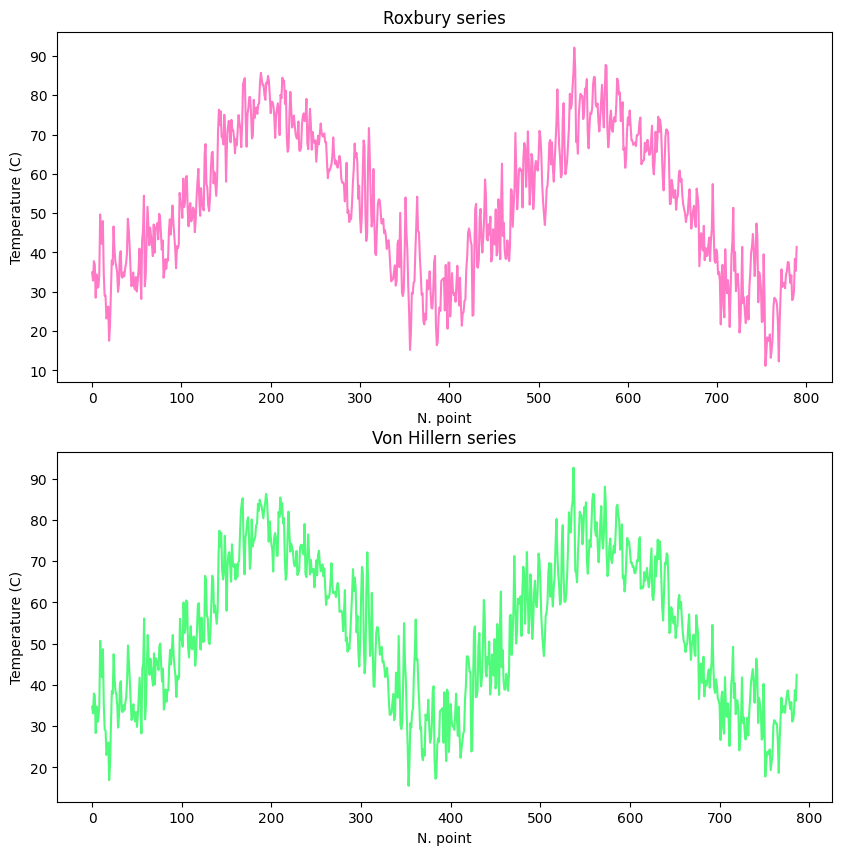

In [15]:
#Let's check the unique sites that we have
import numpy as np
from dotenv import load_dotenv

load_dotenv() 

unique_places = np.unique(list(temperature_data["site_name"]))
print(unique_places)

#OK, let's structure our analysis a little bit. 
class TimeSeriesPoint:

    def __init__(self, place, value, date):
        self.place = place
        self.value = value
        self.date = date
    
import os
PINK_DRACULA = os.environ.get('DRACULA_PINK')
GREEN_DRACULA = os.environ.get('DRACULA_GREEN')

print(PINK_DRACULA)

temp_avg_temperature = list(temperature_data["temp_f"])
dates = list(temperature_data["date"])
places = list(temperature_data["site_name"])

print(f"Points temperature {len(temp_avg_temperature)}")
print(f"Points dates {len(dates)}")
time_series = []
n_points = len(temp_avg_temperature)
for i in range(0,n_points):
    value = temp_avg_temperature[i]
    date = dates[i]
    place = places[i]
    print(place)
    print(date)
    #Point
    point = TimeSeriesPoint(
        place = place,
        value = value,
        date = date
    )
    time_series.append(point)



roxbury_temp_series = [x for x in time_series if x.place == "DUDLEY SQUARE ROXBURY"]
von_hillern_st_temp_series = [x for x in time_series if x.place == "VON HILLERN ST"]


import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 1, figsize = (10, 10))
ax[0].plot([x.value for x in roxbury_temp_series], color = PINK_DRACULA)
ax[0].set_title("Roxbury series")
ax[0].set_ylabel("Temperature (C)")
ax[0].set_xlabel("N. point")

ax[1].plot([x.value for x in von_hillern_st_temp_series], color = GREEN_DRACULA)
ax[1].set_title("Von Hillern series")
ax[1].set_ylabel("Temperature (C)")
ax[1].set_xlabel("N. point")




In [16]:
#Ok, now we'll need to import our own

DATA_PATH_SRC_OURS = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/sensors")

sensor_name_to_file = {
    "Boston Carter Field (ours)": "boston_carter_field/boston_carter_field.csv",
    "Boston Carter Field (ref)": "boston_carter_field_reference/MOD-00157-CarterField.csv",
    "Boston Robinson Hall": "boston_robinson_hall/boston_robinson_hall.csv",
    "Boston Gainsborough Parking": "boston_gainsborough_parking/boston_gainsborough_parking.csv",
    "Boston West Village B": "boston_west_village_b/boston_west_village_b.csv",
    "Boston World Series Way":"boston_world_series_way/boston_world_series_way.csv"
}

sensor_names = list(sensor_name_to_file.keys())
data_boston = {}
for i in range(0,len(sensor_names)):
    sensor_name = sensor_names[i]
    complete_file_path = DATA_PATH_SRC_OURS/sensor_name_to_file[sensor_name]
    data_boston[sensor_name] = pd.read_csv(complete_file_path)

roxbury_data["temperature"] = roxbury_data["temp_f"]
hillern_data["temperature"] = hillern_data["temp_f"]
data_boston["Boston Carter Field (ref)"]["temperature"] = data_boston["Boston Carter Field (ref)"]["temp"]
roxbury_data["timestamp"] = roxbury_data["date"]
hillern_data["timestamp"] = hillern_data["date"]

import sys
sys.path.append("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/src/time_series")
from series_aligner import align_sensor_series_from_list

aligned_df, info = align_sensor_series_from_list(
    sensor_dataframes = [roxbury_data, hillern_data] + [data_boston[key] for key in sensor_names],
    variable_name = "temperature",
    time_column = "timestamp",
    sensor_names = ["Roxbury (EPA)", "Von Hillern (EPA)"] + sensor_names,
    sampling_interval = "24h",
    min_sensors=8
)



array([<Axes: title={'center': 'Roxbury (EPA)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Von Hillern (EPA)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Carter Field (ours)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Carter Field (ref)'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Robinson Hall'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston Gainsborough Parking'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston West Village B'}, xlabel='Time', ylabel='Value'>,
       <Axes: title={'center': 'Boston World Series Way'}, xlabel='Time', ylabel='Value'>],
      dtype=object)

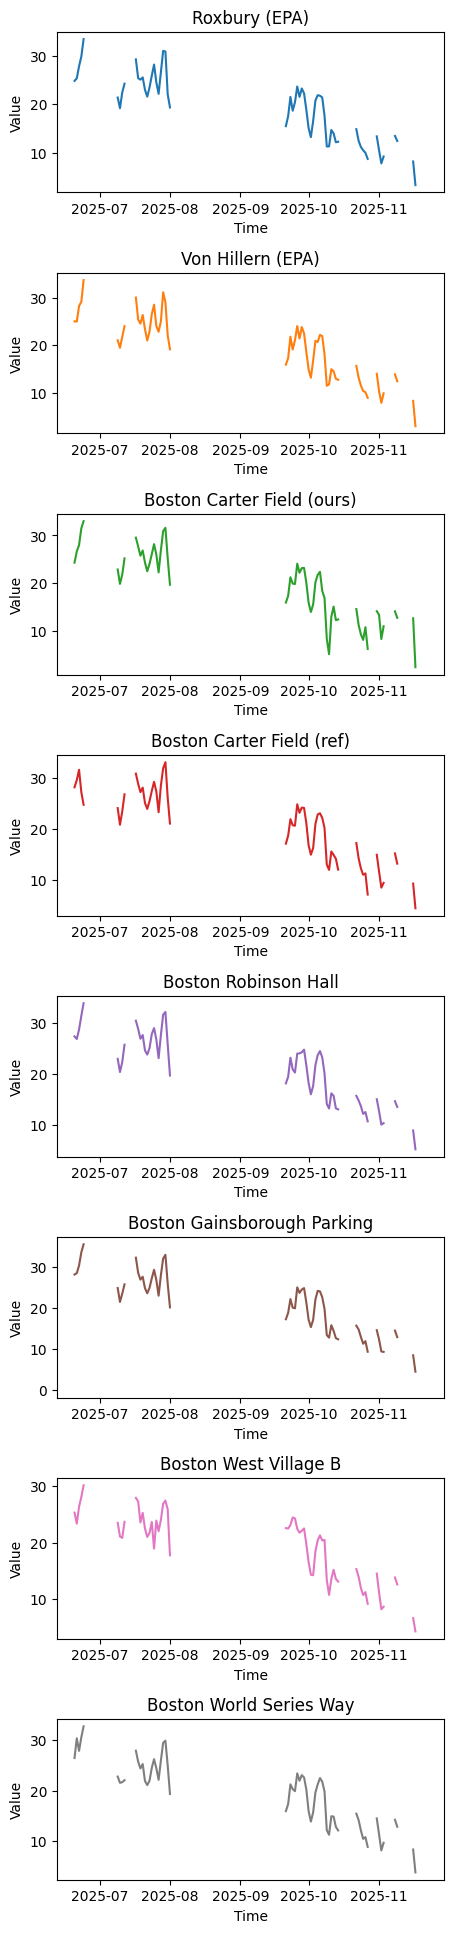

In [17]:
extended_keys = ["Roxbury (EPA)", "Von Hillern (EPA)"] + sensor_names
sys.path.append("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/src/visualization")

from time_series_plotter import TimeSeriesPlotter
from datetime import timedelta
plotter = TimeSeriesPlotter()



plotter.plot(
    list(aligned_df.index),
    time_series_data = [list(aligned_df[key]) for key in list(aligned_df.keys())],
    max_gap = timedelta(hours = 24),
    titles = extended_keys
)

In [18]:
aligned_df.head(10)

,Roxbury (EPA),Von Hillern (EPA),Boston Carter Field (ours),Boston Carter Field (ref),Boston Robinson Hall,Boston Gainsborough Parking,Boston West Village B,Boston World Series Way
timestamp,,,,,,,,
2025-06-20,24.791667,25.023148,24.302500,28.194722,27.308993,28.071952,25.273596,26.471250
2025-06-21,25.324074,24.976852,26.648192,29.623264,26.804161,28.393715,23.331839,30.382084
2025-06-22,27.800926,28.263889,27.994891,31.641181,28.652778,30.265445,26.317069,27.887021
2025-06-23,29.814815,29.143518,31.503298,27.211597,31.338192,33.461183,28.021379,30.592500
2025-06-24,33.402778,33.726852,33.001191,24.748657,33.789468,35.413214,30.087241,32.747979
2025-07-03,26.550926,27.314815,28.236596,29.199653,29.133507,30.722065,25.813563,22.832500
2025-07-09,21.365741,21.018518,22.861250,24.098403,22.928993,24.804138,23.466149,22.803571
2025-07-10,19.166667,19.444444,19.845833,20.815694,20.359583,21.429825,21.050511,21.569149
2025-07-11,22.407407,21.712963,21.790395,23.435278,22.285139,23.432882,20.824081,21.700425


## One to one comparisons with the EPA stations

Let's get the distance to the stations. 

In [19]:
import numpy as np

DATA_PATH_SPATIAL = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/spatial/data-1775857265051.csv")
sensor_locations_data = pd.read_csv(DATA_PATH_SPATIAL)

sensor_name_to_location_name = {
    "Boston Carter Field (ours)": "Carter Field",
    "Boston Robinson Hall": "Robinson Hall",
    "Boston Gainsborough Parking": "Gainsborough Parking Garage",
    "Boston West Village B": "West Village B",
    "Boston World Series Way": "World Series Way"
}

sensor_name_to_coordinates = {}
for sensor_name in sensor_name_to_location_name:
    location_name = sensor_name_to_location_name[sensor_name]
    location_row = sensor_locations_data[sensor_locations_data["ecohub_location"].str.strip() == location_name]
    sensor_name_to_coordinates[sensor_name] = (float(location_row["lat"].iloc[0]), float(location_row["lon"].iloc[0]))

reference_sensor_data = data_boston["Boston Carter Field (ref)"]
sensor_name_to_coordinates["Boston Carter Field (ref)"] = (
    float(reference_sensor_data["lat"].dropna().iloc[0]),
    float(reference_sensor_data["lon"].dropna().iloc[0])
)

epa_station_to_coordinates = {
    "Roxbury (EPA)": (float(roxbury_data["lat"].iloc[0]), float(roxbury_data["lon"].iloc[0])),
    "Von Hillern (EPA)": (float(hillern_data["lat"].iloc[0]), float(hillern_data["lon"].iloc[0]))
}

EARTH_RADIUS_KM = 6371.0

def haversine_distance(coordinates_1, coordinates_2):
    latitude_1, longitude_1 = np.radians(coordinates_1)
    latitude_2, longitude_2 = np.radians(coordinates_2)

    delta_latitude = latitude_2 - latitude_1
    delta_longitude = longitude_2 - longitude_1

    a = np.sin(delta_latitude/2)**2 + np.cos(latitude_1)*np.cos(latitude_2)*np.sin(delta_longitude/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(a))


distance_dictionary = {}
for sensor_name in sensor_names:
    sensor_coordinates = sensor_name_to_coordinates[sensor_name]
    distance_dictionary[sensor_name] = {
        "distance_to_roxbury": haversine_distance(sensor_coordinates, epa_station_to_coordinates["Roxbury (EPA)"]),
        "distance_to_von_hillern": haversine_distance(sensor_coordinates, epa_station_to_coordinates["Von Hillern (EPA)"])
    }

for sensor_name in sensor_names:
    distance_to_roxbury = distance_dictionary[sensor_name]["distance_to_roxbury"]
    distance_to_von_hillern = distance_dictionary[sensor_name]["distance_to_von_hillern"]
    print(f"{sensor_name}: {distance_to_roxbury:.2f} km to Roxbury, {distance_to_von_hillern:.2f} km to Von Hillern")


Boston Carter Field (ours): 1.09 km to Roxbury, 2.80 km to Von Hillern
Boston Carter Field (ref): 0.99 km to Roxbury, 2.79 km to Von Hillern
Boston Robinson Hall: 1.12 km to Roxbury, 2.95 km to Von Hillern
Boston Gainsborough Parking: 1.23 km to Roxbury, 2.92 km to Von Hillern
Boston West Village B: 1.21 km to Roxbury, 3.29 km to Von Hillern
Boston World Series Way: 1.19 km to Roxbury, 3.16 km to Von Hillern


In [20]:
import matplotlib.pyplot as plt
from datetime import timedelta
from time_series_comparison_metrics import compute_rmse, compute_correlation_coefficient

epa_station_to_data = {
    "Roxbury (EPA)": roxbury_data,
    "Von Hillern (EPA)": hillern_data
}

epa_station_to_distance_key = {
    "Roxbury (EPA)": "distance_to_roxbury",
    "Von Hillern (EPA)": "distance_to_von_hillern"
}

metrics_dictionary = {}

def compare_sensor_with_epa_station(sensor_name, epa_station_name, ax):
    aligned_pair, pair_info = align_sensor_series_from_list(
        sensor_dataframes = [epa_station_to_data[epa_station_name], data_boston[sensor_name]],
        variable_name = "temperature",
        time_column = "timestamp",
        sensor_names = [epa_station_name, sensor_name],
        sampling_interval = "24h"
    )

    distance_to_station = distance_dictionary[sensor_name][epa_station_to_distance_key[epa_station_name]]

    plotter.plot(
        list(aligned_pair.index),
        time_series_data = [list(aligned_pair[epa_station_name]), list(aligned_pair[sensor_name])],
        show_in_same_plot = True,
        labels = [epa_station_name, sensor_name],
        y_labels = ["Temperature (C)"],
        titles = [f"{sensor_name} vs {epa_station_name} (dist = {distance_to_station:.2f} km)"],
        rotate_date_labels = True,
        max_gap = timedelta(hours = 24),
        ax = ax
    )

    station_series = list(aligned_pair[epa_station_name])
    sensor_series = list(aligned_pair[sensor_name])

    rmse = compute_rmse(station_series, sensor_series)
    coeff = compute_correlation_coefficient(station_series, sensor_series)

    print(f"{sensor_name} vs {epa_station_name}: {len(aligned_pair)} days in common, rmse = {rmse:.2f}, coeff = {coeff:.3f}")
    return {"rmse": rmse, "coeff": coeff}


def compare_sensor_with_both_stations(sensor_name):
    fig, axes = plt.subplots(1, 2, figsize = (14, 4))
    metrics_dictionary[sensor_name] = {
        "Roxbury (EPA)": compare_sensor_with_epa_station(sensor_name, "Roxbury (EPA)", axes[0]),
        "Von Hillern (EPA)": compare_sensor_with_epa_station(sensor_name, "Von Hillern (EPA)", axes[1])
    }
    fig.tight_layout()
    return metrics_dictionary[sensor_name]


### Boston Carter Field (ours)

Boston Carter Field (ours) vs Roxbury (EPA): 185 days in common, rmse = 1.58, coeff = 0.989
Boston Carter Field (ours) vs Von Hillern (EPA): 185 days in common, rmse = 1.83, coeff = 0.987


{'Roxbury (EPA)': {'rmse': np.float64(1.5783755679552138),
  'coeff': np.float64(0.9888146362968294)},
 'Von Hillern (EPA)': {'rmse': np.float64(1.8256496078523992),
  'coeff': np.float64(0.9868177425537171)}}

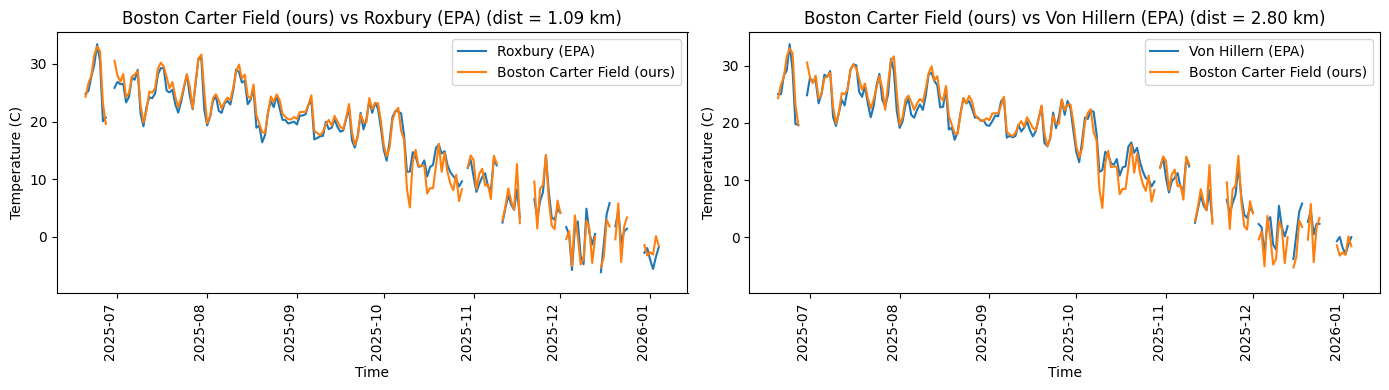

In [21]:
compare_sensor_with_both_stations("Boston Carter Field (ours)")


### Boston Carter Field (ref)

Boston Carter Field (ref) vs Roxbury (EPA): 140 days in common, rmse = 4.18, coeff = 0.849
Boston Carter Field (ref) vs Von Hillern (EPA): 140 days in common, rmse = 4.22, coeff = 0.839


{'Roxbury (EPA)': {'rmse': np.float64(4.180307212072947),
  'coeff': np.float64(0.848796402503032)},
 'Von Hillern (EPA)': {'rmse': np.float64(4.217570351682041),
  'coeff': np.float64(0.8389335959617884)}}

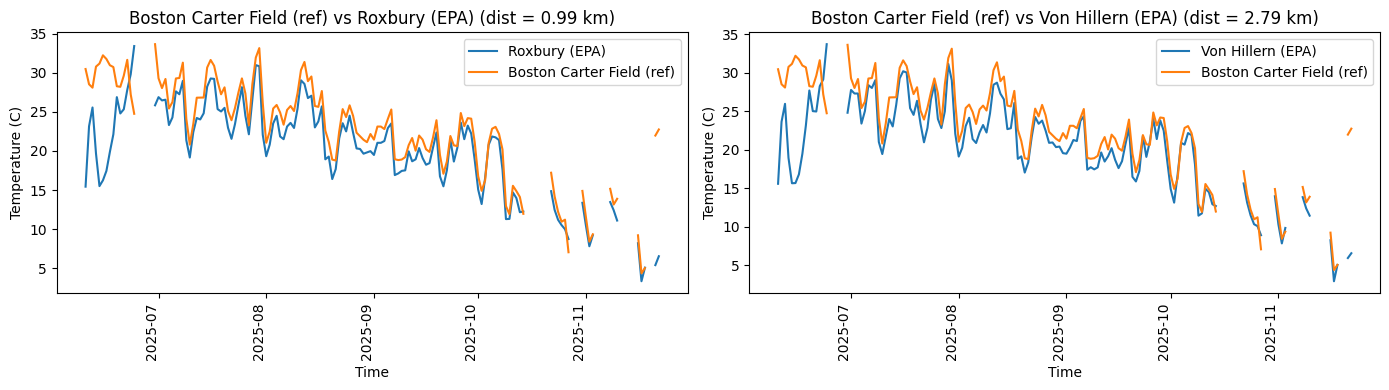

In [22]:
compare_sensor_with_both_stations("Boston Carter Field (ref)")


### Boston Robinson Hall

Boston Robinson Hall vs Roxbury (EPA): 447 days in common, rmse = 2.00, coeff = 0.995
Boston Robinson Hall vs Von Hillern (EPA): 447 days in common, rmse = 1.91, coeff = 0.992


{'Roxbury (EPA)': {'rmse': np.float64(2.0045134195402223),
  'coeff': np.float64(0.9949929307060241)},
 'Von Hillern (EPA)': {'rmse': np.float64(1.907051160068526),
  'coeff': np.float64(0.9923202497981914)}}

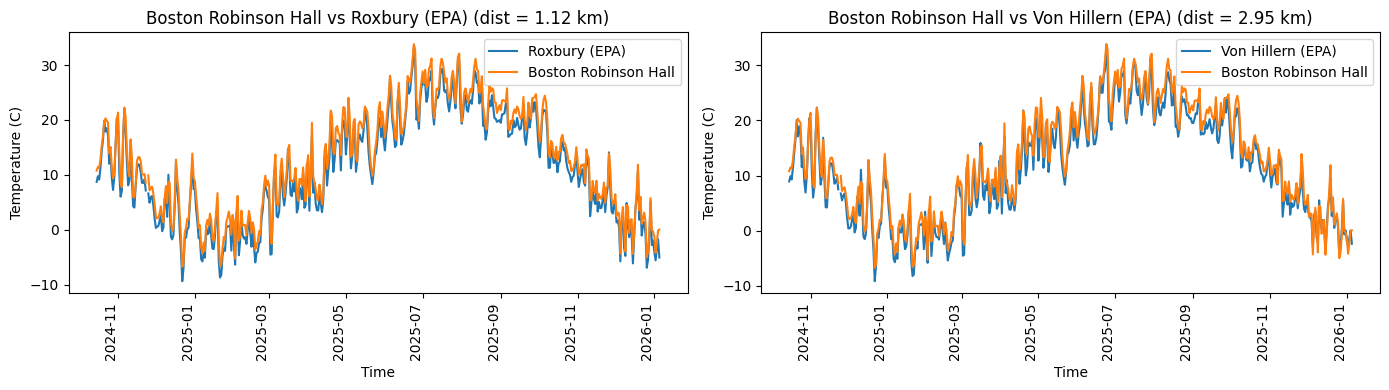

In [23]:
compare_sensor_with_both_stations("Boston Robinson Hall")


### Boston Gainsborough Parking

Boston Gainsborough Parking vs Roxbury (EPA): 377 days in common, rmse = 3.50, coeff = 0.967
Boston Gainsborough Parking vs Von Hillern (EPA): 377 days in common, rmse = 3.50, coeff = 0.964


{'Roxbury (EPA)': {'rmse': np.float64(3.4953997353204955),
  'coeff': np.float64(0.9670589564868308)},
 'Von Hillern (EPA)': {'rmse': np.float64(3.4979972137557858),
  'coeff': np.float64(0.9635325998418682)}}

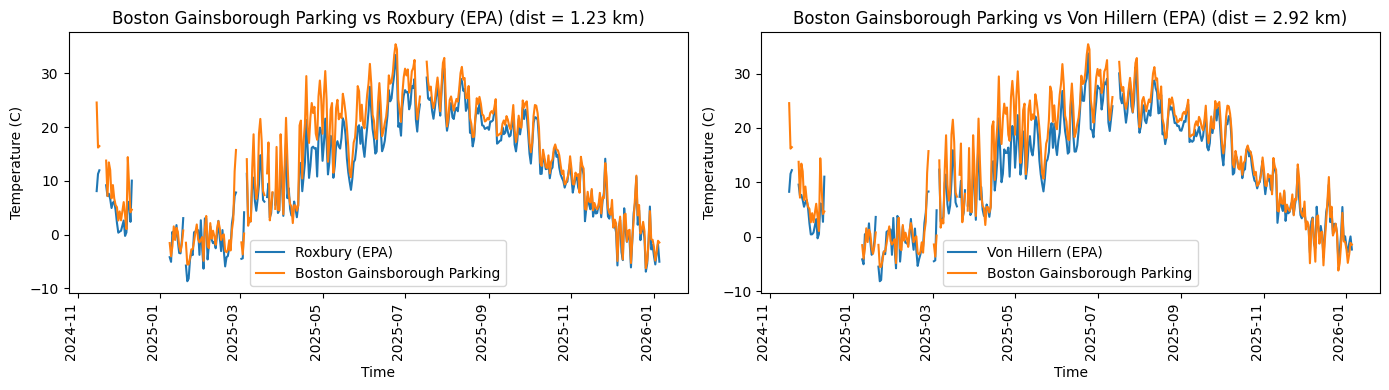

In [24]:
compare_sensor_with_both_stations("Boston Gainsborough Parking")


### Boston West Village B

Boston West Village B vs Roxbury (EPA): 363 days in common, rmse = 1.96, coeff = 0.981
Boston West Village B vs Von Hillern (EPA): 363 days in common, rmse = 1.97, coeff = 0.978


{'Roxbury (EPA)': {'rmse': np.float64(1.9647427048584036),
  'coeff': np.float64(0.9805097777924329)},
 'Von Hillern (EPA)': {'rmse': np.float64(1.9740589417604566),
  'coeff': np.float64(0.9775204792845359)}}

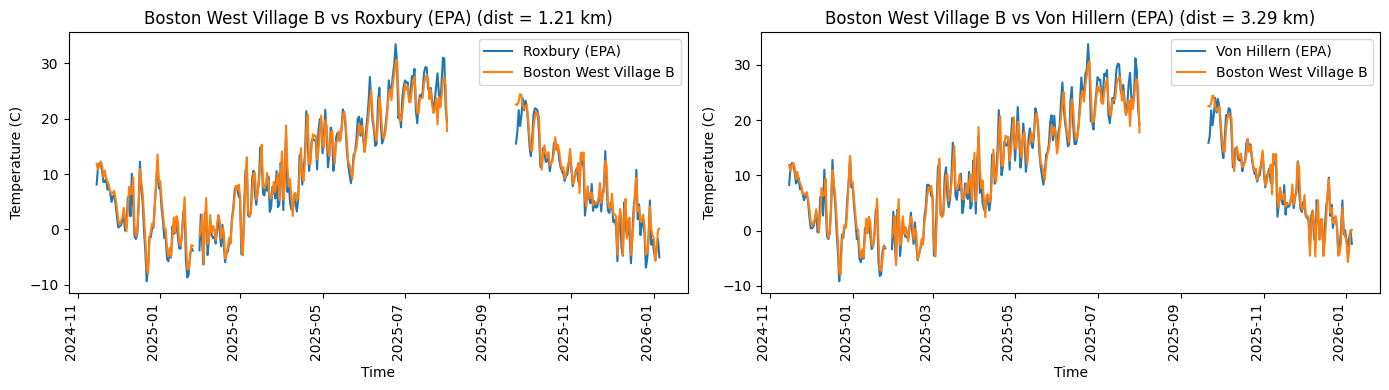

In [25]:
compare_sensor_with_both_stations("Boston West Village B")


### Boston World Series Way

Boston World Series Way vs Roxbury (EPA): 341 days in common, rmse = 1.81, coeff = 0.987
Boston World Series Way vs Von Hillern (EPA): 341 days in common, rmse = 1.79, coeff = 0.984


{'Roxbury (EPA)': {'rmse': np.float64(1.809807352894252),
  'coeff': np.float64(0.987415558270601)},
 'Von Hillern (EPA)': {'rmse': np.float64(1.7875860233738106),
  'coeff': np.float64(0.9840439865322134)}}

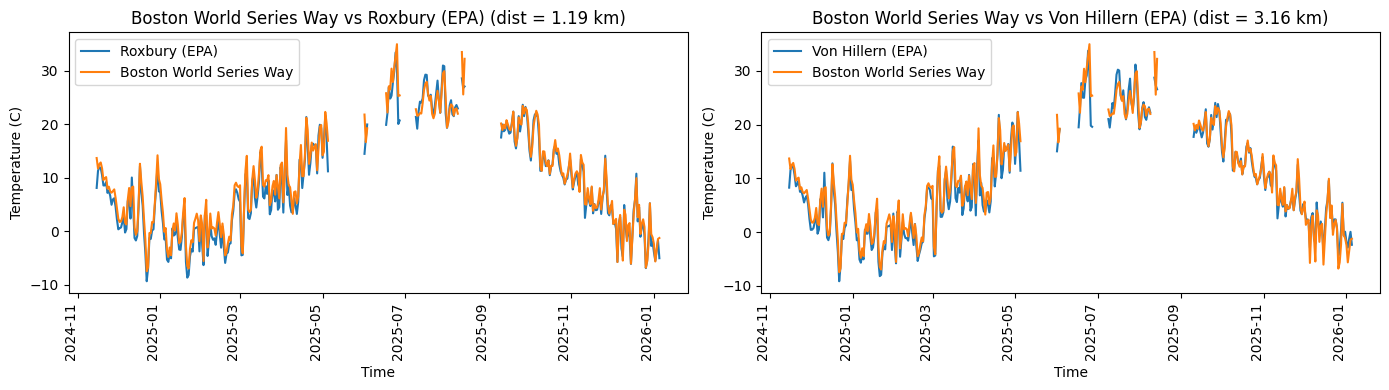

In [26]:
compare_sensor_with_both_stations("Boston World Series Way")


## RMSE and correlation against each EPA station

In [27]:
from distribution_plotter import DistributionPlotter

sensor_name_to_abbreviation = {
    "Boston Carter Field (ours)": "Carter (ours)",
    "Boston Carter Field (ref)": "Carter (ref)",
    "Boston Robinson Hall": "Robinson",
    "Boston Gainsborough Parking": "Gainsborough",
    "Boston West Village B": "West Village B",
    "Boston World Series Way": "World Series"
}

distribution_plotter = DistributionPlotter()
sensor_abbreviations = [sensor_name_to_abbreviation[sensor_name] for sensor_name in sensor_names]

def plot_metric_for_both_stations(metric_name, variable_name, title, decimals = 2, delta = 0.05, ylims = None, distance_between_values = 0.2):
    distributions = [
        {
            "x": sensor_abbreviations,
            "y": [metrics_dictionary[sensor_name]["Roxbury (EPA)"][metric_name] for sensor_name in sensor_names],
            "color_bars": PINK_DRACULA,
            "label": "Roxbury (EPA)"
        },
        {
            "x": sensor_abbreviations,
            "y": [metrics_dictionary[sensor_name]["Von Hillern (EPA)"][metric_name] for sensor_name in sensor_names],
            "color_bars": GREEN_DRACULA,
            "label": "Von Hillern (EPA)"
        }
    ]

    return distribution_plotter.multi_distribution_plotter(
        distributions,
        width = 16,
        height = 5,
        variable_name = variable_name,
        title = title,
        values_on_top = True,
        decimals = decimals,
        delta = delta,
        ylims = ylims,
        distance_between_values = distance_between_values
    )


<Axes: title={'center': 'RMSE of each sensor against the EPA stations'}, ylabel='RMSE (C)'>

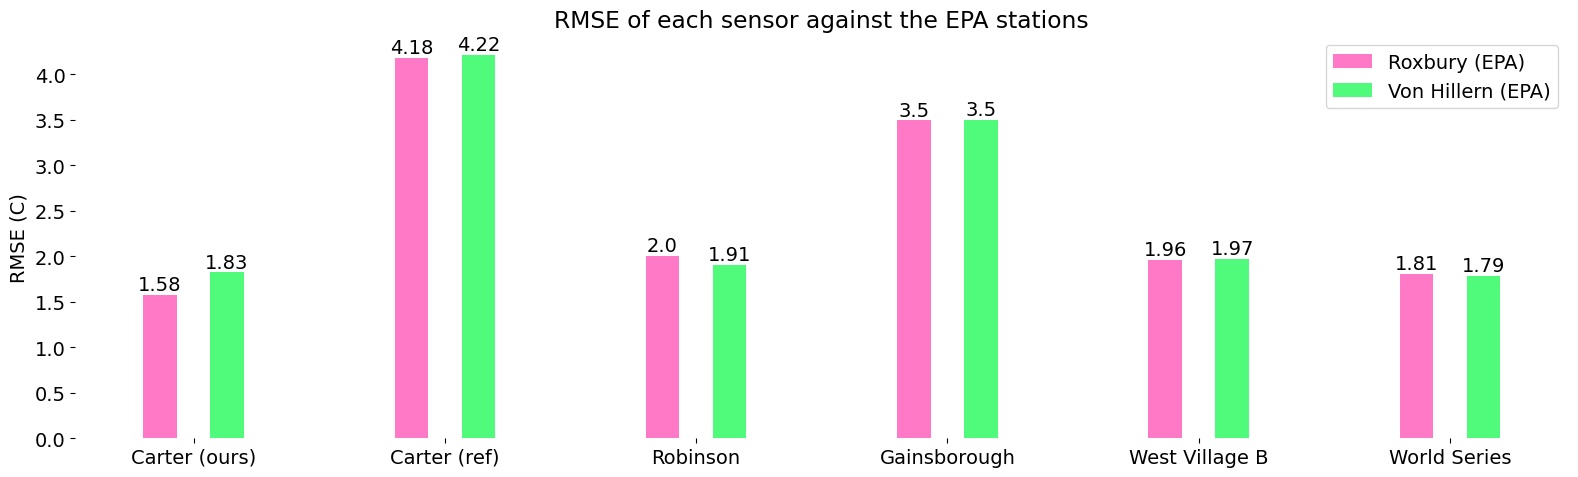

In [28]:
plot_metric_for_both_stations(
    "rmse",
    variable_name = "RMSE (C)",
    title = "RMSE of each sensor against the EPA stations",
    decimals = 2,
    delta = 0.05
)


<Axes: title={'center': 'Correlation of each sensor with the EPA stations'}, ylabel='Correlation coefficient'>

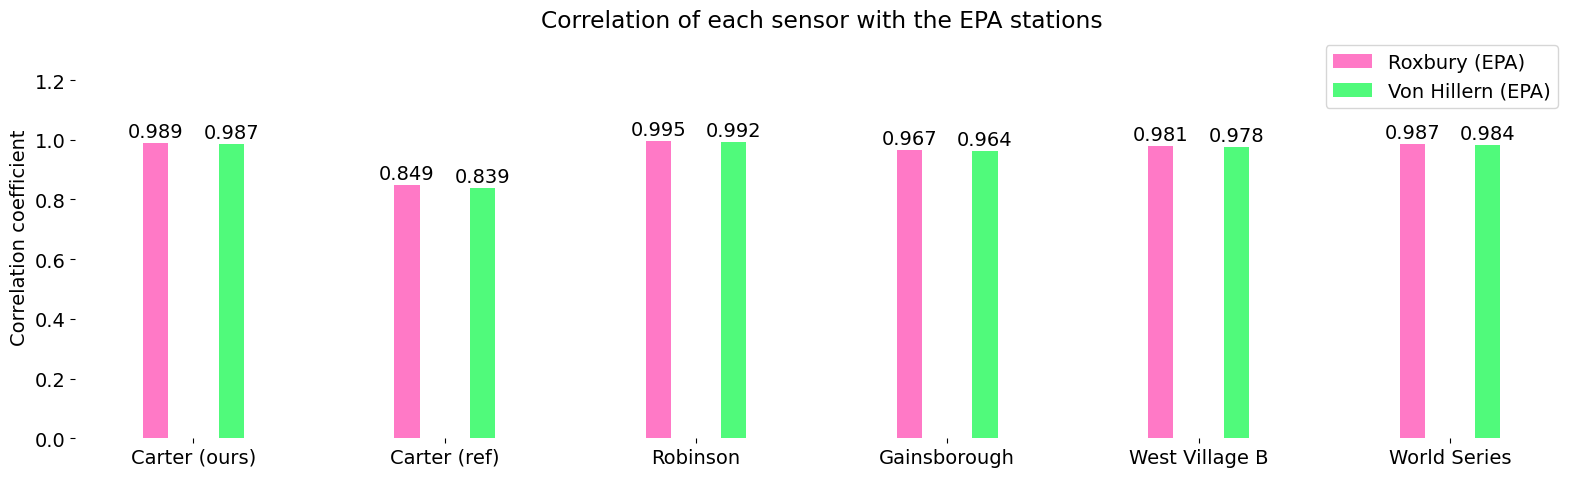

In [29]:
plot_metric_for_both_stations(
    "coeff",
    variable_name = "Correlation coefficient",
    title = "Correlation of each sensor with the EPA stations",
    decimals = 3,
    delta = 0.02,
    ylims = [0, 1.35],
    distance_between_values = 0.4
)
